# Продуктовая аналитика мобильного приложения ShopFlow

**Контекст.** ShopFlow — мобильное приложение интернет-магазина (данные синтетические, сгенерированы скриптом `src/generate_data.py`). Период наблюдений: **1 июля — 30 сентября 2025**, 12 000 зарегистрированных пользователей.

**Задачи анализа**
1. Проверить качество данных и найти аномалии.
2. Посчитать ключевые продуктовые метрики: DAU / MAU, sticky factor.
3. Построить воронку от открытия приложения до покупки и найти самый слабый шаг.
4. Оценить удержание пользователей (retention) по когортам, каналам и платформам.
5. Сравнить монетизацию сегментов (ARPU, доля платящих).
6. Подвести итоги A/B-теста нового экрана оформления заказа и дать рекомендацию.

**Стек:** Python (pandas, NumPy, SciPy, matplotlib, seaborn), SQL (SQLite).

## 0. Подготовка

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from build_db import build  # noqa: E402

DB_PATH = ROOT / "data" / "shopflow.db"
SQL_DIR = ROOT / "sql"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
END_DATE = pd.Timestamp("2025-09-30")

if not DB_PATH.exists():          # база собирается из CSV одной командой
    build(DB_PATH)
con = sqlite3.connect(DB_PATH)

def run_sql(name: str) -> pd.DataFrame:
    """Выполнить запрос из папки sql/ и вернуть DataFrame."""
    return pd.read_sql((SQL_DIR / name).read_text(encoding="utf-8"), con)

# единый стиль графиков
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)

База создана: /home/claude/product-analytics-ab-test/data/shopflow.db  (events: 281,877)

## 1. Знакомство с данными

| Таблица | Содержимое |
|---|---|
| `users` | пользователь, время регистрации, платформа, канал привлечения, город |
| `events` | события в приложении: `app_open`, `view_product`, `add_to_cart`, `checkout`, `purchase` (+ сумма покупки) |
| `ab_groups` | группа A/B-теста для пользователей, зарегистрированных 15.08–14.09 |

Сначала смотрим на **сырые** CSV, чтобы увидеть проблемы до очистки.

In [2]:
raw_users = pd.read_csv(ROOT / "data/raw/users.csv", parse_dates=["registration_time"])
raw_events = pd.read_csv(ROOT / "data/raw/events.csv", parse_dates=["event_time"])
raw_ab = pd.read_csv(ROOT / "data/raw/ab_groups.csv")

for name, df in [("users", raw_users), ("events", raw_events), ("ab_groups", raw_ab)]:
    print(f"{name:<10} {df.shape[0]:>8,} строк × {df.shape[1]} столбцов")
raw_events.head()

users        12,000 строк × 5 столбцов
events      283,850 строк × 5 столбцов
ab_groups     4,363 строк × 2 столбцов

,event_id,user_id,event_time,event_type,revenue
0,1,106587,2025-07-01 00:51:30,app_open,NaN
1,2,106587,2025-07-01 00:53:16,view_product,NaN
2,3,106587,2025-07-01 00:53:58,view_product,NaN
3,4,106587,2025-07-01 00:55:01,view_product,NaN
4,5,102922,2025-07-01 01:18:43,app_open,NaN


## 2. Качество данных

In [3]:
dups = raw_events.duplicated(subset=["user_id", "event_time", "event_type"]).sum()
print(f"Дубликаты событий:            {dups:,} ({dups / len(raw_events):.2%})")
print(f"Пропуски платформы у юзеров:  {raw_users['platform'].isna().sum():,}")
print(f"Пропуски revenue у покупок:   {raw_events.query('event_type == \"purchase\"')['revenue'].isna().sum()}")
print(f"Отрицательные суммы покупок:  {(raw_events['revenue'] < 0).sum()}")
print(f"Пользователи без событий:     {(~raw_users['user_id'].isin(raw_events['user_id'])).sum()}")
print(f"Период событий: {raw_events['event_time'].min()} — {raw_events['event_time'].max()}")

Дубликаты событий:            1,973 (0.70%)
Пропуски платформы у юзеров:  240
Пропуски revenue у покупок:   0
Отрицательные суммы покупок:  0
Пользователи без событий:     2
Период событий: 2025-07-01 00:51:30 — 2025-09-30 23:59:45

**Что делаем с проблемами** (это реализовано в `src/build_db.py` при загрузке в SQLite):
- дубликаты событий (≈0.7%) удаляем — иначе завысим число покупок и выручку;
- пропуски платформы (≈2% пользователей) помечаем как `unknown` и не используем в сравнении платформ;
- пользователи без событий есть, но их единицы — оставляем.

Дальше работаем с очищенными данными из базы.

In [4]:
users = pd.read_sql("SELECT * FROM users", con, parse_dates=["registration_time"])
events = pd.read_sql("SELECT * FROM events", con, parse_dates=["event_time"])
ab = pd.read_sql("SELECT * FROM ab_groups", con)
print(f"Событий после очистки: {len(events):,}")
events["event_type"].value_counts().to_frame("events")

Событий после очистки: 281,877

,events
event_type,
view_product,201333
app_open,50272
add_to_cart,16084
checkout,8893
purchase,5295


## 3. Активность: DAU / MAU

Аномальные дни:
            dau  median_7d
event_time                
2025-08-03   68     461.00

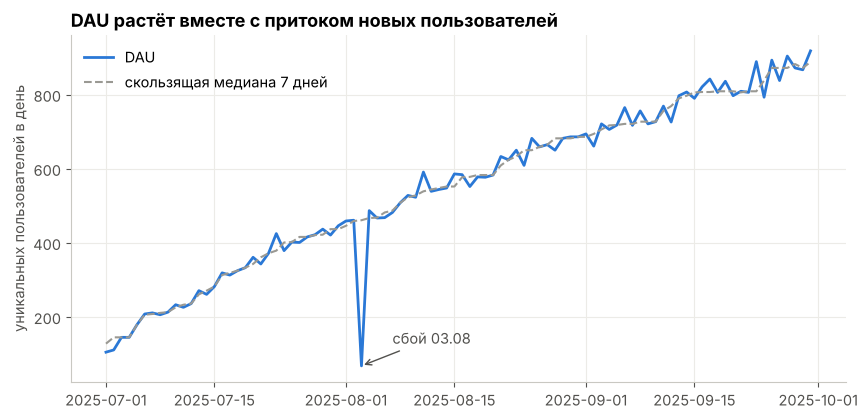

In [5]:
dau = (events.query("event_type == 'app_open'")
              .groupby(events["event_time"].dt.normalize())["user_id"].nunique()
              .rename("dau"))

# аномалия: день, где DAU сильно ниже скользящей медианы за неделю
rolling = dau.rolling(7, center=True, min_periods=3).median()
anomalies = dau[dau < 0.5 * rolling]
print("Аномальные дни:")
print(anomalies.to_frame().assign(median_7d=rolling[anomalies.index]))

fig, ax = plt.subplots()
ax.plot(dau.index, dau, color=BLUE, lw=2, label="DAU")
ax.plot(rolling.index, rolling, color=GREY, lw=1.5, ls="--", label="скользящая медиана 7 дней")
for day in anomalies.index:
    ax.annotate(f"сбой {day:%d.%m}", xy=(day, dau[day]), xytext=(day + pd.Timedelta(days=4), dau[day] + 60),
                arrowprops=dict(arrowstyle="->", color="#52514e"), color="#52514e")
ax.set_title("DAU растёт вместе с притоком новых пользователей")
ax.set_ylabel("уникальных пользователей в день")
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "01_dau.png", bbox_inches="tight")
plt.show()

**Это реальное падение или сбой?** Проверим две независимые таблицы. Регистрации записываются в `users` (отдельно от логов), а действия пользователей — в `events`. Если люди в этот день действительно не пользовались приложением, регистраций тоже должно быть мало. Если регистраций обычное количество, а событий у этих же новых пользователей нет, — значит, не записались логи.

In [6]:
# регистрации по дням — из таблицы users
registrations = users.groupby(users["registration_time"].dt.normalize())["user_id"].nunique()

# сколько из зарегистрировавшихся в этот день имеют хотя бы одно событие в тот же день
reg_day = users[["user_id"]].assign(day=users["registration_time"].dt.normalize())
ev_day = events[["user_id"]].assign(day=events["event_time"].dt.normalize()).drop_duplicates()
new_with_events = reg_day.merge(ev_day, on=["user_id", "day"]).groupby("day")["user_id"].nunique()

events_per_day = events.groupby(events["event_time"].dt.normalize()).size()

outage_check = pd.DataFrame({
    "регистрации": registrations,
    "новички с событиями": new_with_events,
    "DAU": dau,
    "всего событий": events_per_day,
}).loc["2025-07-31":"2025-08-06"]
outage_check["доля новичков с событиями"] = (outage_check["новички с событиями"] / outage_check["регистрации"]).map("{:.0%}".format)
outage_check

,регистрации,новички с событиями,DAU,всего событий,доля новичков с событиями
2025-07-31,122,122,446,2487,100%
2025-08-01,112,112,459,2587,100%
2025-08-02,122,122,461,2638,100%
2025-08-03,115,9,68,384,8%
2025-08-04,131,131,487,2650,100%
2025-08-05,124,124,467,2701,100%
2025-08-06,128,128,468,2627,100%


3 августа зарегистрировались **115** человек — столько же, сколько в соседние дни. Но события в день регистрации есть только у **9** из них (8%), хотя обычно они есть у 100% новичков: регистрация сразу открывает приложение. Пользователи были, а их действия не попали в логи — это **сбой логирования**, а не отток.

In [7]:
run_sql("01_dau_mau.sql")

,month,mau,avg_dau,sticky_factor_pct
0,2025-07,3472,295.00,8.50
1,2025-08,6970,560.00,8.00
2,2025-09,10213,792.00,7.80


**Выводы по активности**
- DAU растёт с ~300 в июле до ~800 в сентябре — за счёт роста регистраций.
- **3 августа** — провал DAU примерно в 7 раз (68 пользователей против медианы ~460) относительно соседних дней. При этом регистраций в этот день обычное количество (115), а события есть только у 9 из этих новичков — значит, это сбой логирования, а не реальное падение (проверка выше). Этот день нужно учитывать при интерпретации метрик за август (например, retention когорты 28.07–03.08).
- Sticky factor (DAU/MAU) ≈ 8% и слегка снижается: доля «новичков», которые заходят один раз, растёт быстрее, чем ядро постоянной аудитории.

## 4. Воронка покупки

In [8]:
funnel = run_sql("02_funnel.sql")
funnel

,step_no,step,users,conv_from_start_pct,conv_from_prev_pct
0,1,app_open,11998,100.00,NaN
1,2,view_product,11997,100.00,100.00
2,3,add_to_cart,8664,72.20,72.20
3,4,checkout,6202,51.70,71.60
4,5,purchase,4247,35.40,68.50


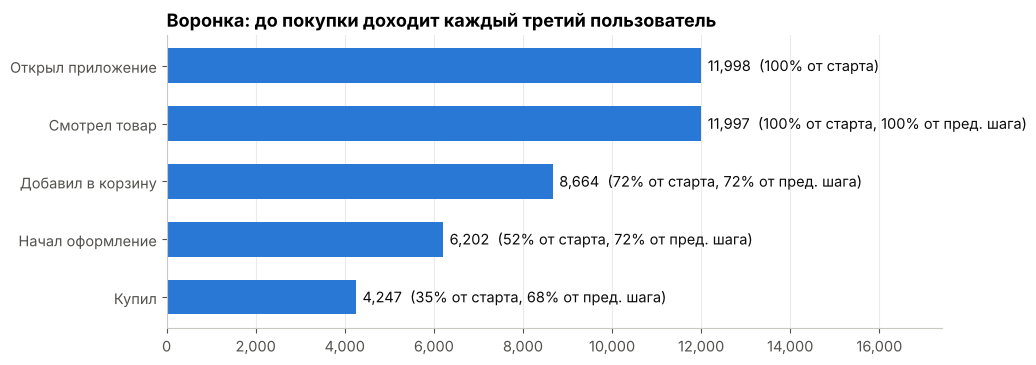

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = {"app_open": "Открыл приложение", "view_product": "Смотрел товар",
          "add_to_cart": "Добавил в корзину", "checkout": "Начал оформление", "purchase": "Купил"}
y = funnel["step"].map(labels)[::-1]
x = funnel["users"][::-1]
ax.barh(y, x, color=BLUE, height=0.6)
for yi, (users_n, pct, prev) in enumerate(zip(x, funnel["conv_from_start_pct"][::-1], funnel["conv_from_prev_pct"][::-1])):
    note = f"{users_n:,}  ({pct:.0f}% от старта" + (f", {prev:.0f}% от пред. шага)" if pd.notna(prev) else ")")
    ax.text(users_n + 150, yi, note, va="center", color="#0b0b0b")
ax.set_xlim(0, funnel["users"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Воронка: до покупки доходит каждый третий пользователь")
fig.savefig(FIG_DIR / "02_funnel.png", bbox_inches="tight")
plt.show()

**Выводы по воронке**
- Из всех, кто открыл приложение, хотя бы раз купили **≈35%** пользователей.
- Самые большие потери — на шагах «смотрел товар → корзина» (−28%) и «оформление → покупка» (−31%).
- Потеря почти трети пользователей уже *на* экране оформления — сигнал, что проблема в самом экране (сложная форма, способы оплаты). Именно эту гипотезу проверяли в A/B-тесте (раздел 7).

## 5. Удержание (retention)

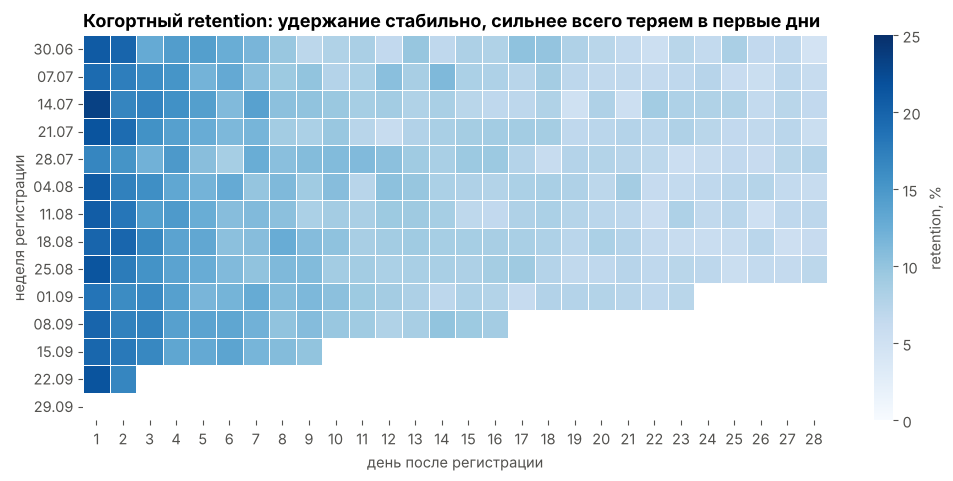

In [10]:
opens = events.query("event_type == 'app_open'")[["user_id", "event_time"]].merge(
    users[["user_id", "registration_time", "source", "platform"]], on="user_id")
opens["day_n"] = (opens["event_time"].dt.normalize() - opens["registration_time"].dt.normalize()).dt.days
opens["cohort"] = opens["registration_time"].dt.to_period("W").dt.start_time

cohort_size = users.groupby(users["registration_time"].dt.to_period("W").dt.start_time)["user_id"].nunique()
active = opens.query("day_n <= 28").groupby(["cohort", "day_n"])["user_id"].nunique().unstack()
retention = active.div(cohort_size, axis=0)

# убираем ячейки, где день N для когорты ещё не наступил целиком
for cohort in retention.index:
    max_day = (END_DATE - (cohort + pd.Timedelta(days=6))).days
    retention.loc[cohort, retention.columns > max_day] = np.nan

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(retention.loc[:, 1:28] * 100, cmap="Blues", ax=ax, vmin=0, vmax=25,
            cbar_kws={"label": "retention, %"}, linewidths=0.5, linecolor="white")
ax.grid(False)
ax.set_yticklabels([d.strftime("%d.%m") for d in retention.index], rotation=0)
ax.set_xlabel("день после регистрации")
ax.set_ylabel("неделя регистрации")
ax.set_title("Когортный retention: удержание стабильно, сильнее всего теряем в первые дни")
fig.savefig(FIG_DIR / "03_retention_heatmap.png", bbox_inches="tight")
plt.show()

In [11]:
run_sql("03_retention.sql")

,cohort_week,cohort_size,retention_d1_pct,retention_d7_pct,retention_d30_pct
0,2025-06-30,619,20.80,11.60,5.50
1,2025-07-07,720,19.30,10.60,4.90
2,2025-07-14,821,23.40,13.90,4.80
3,2025-07-21,823,21.50,11.80,8.60
4,2025-07-28,838,16.70,12.70,6.20
5,2025-08-04,858,21.00,9.90,5.20
6,2025-08-11,911,20.60,11.20,7.80
7,2025-08-18,934,19.90,10.80,6.50
8,2025-08-25,987,21.50,10.20,6.30
9,2025-09-01,1016,18.40,12.80,NaN


Удержание сильно зависит от того, **откуда** пришёл пользователь. Сравним кривые retention по каналам и платформам (учитываем только пользователей, у которых день N уже наступил).

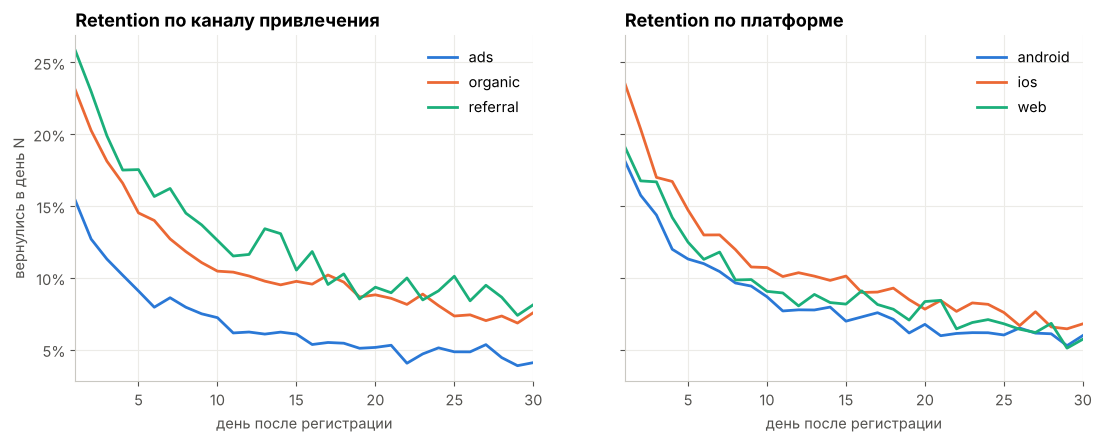

D1    D7  D30
source   ads      15.40  8.60 4.10
         organic  23.10 12.70 7.60
         referral 25.80 16.20 8.10
platform android  18.10 10.40 6.00
         ios      23.50 13.00 6.80
         web      19.10 11.80 5.70

In [12]:
def retention_curve(by: str, days=range(1, 31)) -> pd.DataFrame:
    reg_day = users.set_index("user_id")["registration_time"].dt.normalize()
    res = {}
    for d in days:
        eligible = users[reg_day.values + pd.Timedelta(days=d) <= END_DATE]
        returned = opens.query("day_n == @d")["user_id"].unique()
        res[d] = eligible.assign(ret=eligible["user_id"].isin(returned)).groupby(by)["ret"].mean()
    return pd.DataFrame(res).T

ret_source = retention_curve("source")
ret_platform = retention_curve("platform").drop(columns="unknown")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, data, title in [(axes[0], ret_source, "по каналу привлечения"), (axes[1], ret_platform, "по платформе")]:
    for col, color in zip(data.columns, [BLUE, ORANGE, AQUA]):
        ax.plot(data.index, data[col] * 100, color=color, lw=2, label=col)
    ax.set_title(f"Retention {title}")
    ax.set_xlabel("день после регистрации")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.legend()
    ax.set_xlim(1, 30)
axes[0].set_ylabel("вернулись в день N")
fig.savefig(FIG_DIR / "04_retention_segments.png", bbox_inches="tight")
plt.show()

summary = pd.concat({"source": ret_source.loc[[1, 7, 30]].T, "platform": ret_platform.loc[[1, 7, 30]].T})
(summary * 100).round(1).add_prefix("D")

**Выводы по удержанию**
- D1 ≈ 20%, D7 ≈ 11%, D30 ≈ 6% — от когорты к когорте удержание стабильно, улучшений или ухудшений продукта за квартал не видно.
- Когорта 28.07–03.08 выглядит хуже по D1 — это эффект сбоя логирования 3 августа, а не реальное ухудшение.
- **Пользователи из рекламы (`ads`) удерживаются заметно хуже**, чем органические и пришедшие по рекомендации (`referral`), — при этом это ~40% всех новых пользователей.
- Среди платформ Android отстаёт от iOS — стоит проверить стабильность и скорость Android-приложения.

## 6. Монетизация по сегментам

In [13]:
segments = run_sql("05_revenue_by_segment.sql")
segments

,source,platform,users,paying_share_pct,orders,revenue,arpu,aov
0,referral,ios,633,44.50,382,"818,178.00","1,292.50","2,141.80"
1,organic,ios,1950,42.50,1102,"2,268,797.00","1,163.50","2,058.80"
2,organic,web,749,39.80,371,"842,481.00","1,124.80","2,270.80"
3,referral,android,875,38.30,442,"961,020.00","1,098.30","2,174.30"
4,referral,web,274,39.10,142,"266,520.00",972.70,"1,876.90"
5,organic,android,2515,35.50,1102,"2,308,313.00",917.80,"2,094.70"
6,ads,ios,1865,32.20,706,"1,538,963.00",825.20,"2,179.80"
7,ads,web,711,30.50,253,"493,214.00",693.70,"1,949.50"
8,ads,android,2188,27.40,682,"1,406,026.00",642.60,"2,061.60"


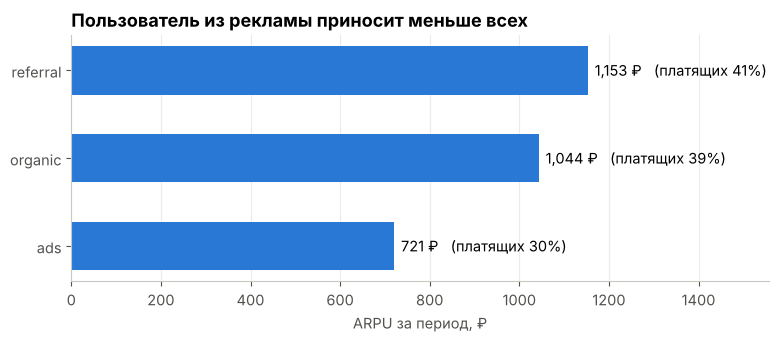

,users,arpu,paying_share
source,,,
ads,4862,720.89,0.30
organic,5320,"1,043.80",0.39
referral,1818,"1,153.21",0.41


In [14]:
by_source = (users.merge(
        events.query("event_type == 'purchase'").groupby("user_id")["revenue"].sum().rename("revenue"),
        on="user_id", how="left").fillna({"revenue": 0})
    .groupby("source").agg(users=("user_id", "size"), arpu=("revenue", "mean"),
                           paying_share=("revenue", lambda s: (s > 0).mean()))
    .sort_values("arpu"))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(by_source.index, by_source["arpu"], color=BLUE, height=0.55)
for i, (v, p) in enumerate(zip(by_source["arpu"], by_source["paying_share"])):
    ax.text(v + 15, i, f"{v:,.0f} ₽   (платящих {p:.0%})", va="center")
ax.set_xlim(0, by_source["arpu"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ARPU за период, ₽")
ax.set_title("Пользователь из рекламы приносит меньше всех")
fig.savefig(FIG_DIR / "05_arpu_by_source.png", bbox_inches="tight")
plt.show()
by_source

**Выводы по монетизации**
- Средний чек (AOV) почти одинаков во всех сегментах (~1 900–2 300 ₽) — различия в выручке создаёт **доля платящих и частота покупок**, а не размер чека.
- ARPU рекламного трафика примерно на 30–40% ниже, чем у органики. Если стоимость привлечения (CAC) в рекламе выше ARPU, канал убыточен — нужно сопоставить с маркетинговыми расходами (в данных их нет).
- Лучший сегмент — `referral` + iOS: высокая доля платящих и удержание. Реферальную программу стоит масштабировать.

## 7. A/B-тест: новый экран оформления заказа

**Гипотеза.** Упрощённый экран оформления заказа (меньше полей, оплата в один клик) увеличит долю пользователей, совершивших покупку.

**Дизайн теста**
- Участники: все новые пользователи, зарегистрированные **15.08–14.09.2025**, случайное разбиение 50/50.
- **Основная метрика:** конверсия в покупку за первые 14 дней после регистрации (доля пользователей с ≥1 покупкой).
- **Дополнительные метрики:** конверсия checkout → purchase, ARPU за 14 дней.
- **Контрольная (guardrail) метрика:** доля дошедших до checkout — новый экран не должен на неё влиять; средний чек не должен упасть.
- Уровень значимости α = 0.05.

### 7.1 Проверка корректности разбиения (SRM)

In [15]:
group_sizes = ab["ab_group"].value_counts().sort_index()
chi2, p_srm = stats.chisquare(group_sizes)
print(group_sizes.to_string())
print(f"\nSRM-тест (χ²): p-value = {p_srm:.3f}  ->  " +
      ("разбиение корректно" if p_srm > 0.01 else "ВНИМАНИЕ: группы несбалансированы!"))

check = ab.merge(users, on="user_id")
pd.crosstab(check["ab_group"], check["platform"], normalize="index").round(3)

ab_group
A    2191
B    2172

SRM-тест (χ²): p-value = 0.774  ->  разбиение корректно

platform,android,ios,unknown,web
ab_group,,,,
A,0.45,0.38,0.02,0.15
B,0.47,0.37,0.02,0.15


Группы сбалансированы по размеру и по составу платформ — можно сравнивать метрики.

### 7.2 Метрики по группам

In [16]:
ab_metrics = run_sql("04_ab_test.sql")
ab_metrics

,ab_group,users,buyers,conversion_pct,checkout_to_purchase_pct,arpu,arppu
0,A,2191,536,24.46,59.96,540.47,"2,209.28"
1,B,2172,594,27.35,70.55,654.78,"2,394.25"


In [17]:
# пользовательские метрики за 14 дней — та же логика, что в SQL, нужна для статистических тестов
part = ab.merge(users[["user_id", "registration_time"]], on="user_id")
ev14 = events.merge(part, on="user_id")
ev14 = ev14[ev14["event_time"] < ev14["registration_time"] + pd.Timedelta(days=14)]

per_user = part.set_index("user_id")[["ab_group"]].join([
    ev14.query("event_type == 'checkout'").groupby("user_id").size().gt(0).rename("checkout"),
    ev14.query("event_type == 'purchase'").groupby("user_id").size().gt(0).rename("purchased"),
    ev14.query("event_type == 'purchase'").groupby("user_id")["revenue"].sum().rename("revenue"),
]).fillna({"checkout": False, "purchased": False, "revenue": 0})

a = per_user[per_user["ab_group"] == "A"]
b = per_user[per_user["ab_group"] == "B"]
print(f"A: {len(a):,} пользователей, B: {len(b):,}")

A: 2,191 пользователей, B: 2,172

### 7.3 Основная метрика: конверсия в покупку

Используем **z-тест для двух долей** и строим 95% доверительный интервал для разницы.

In [18]:
def z_test_proportions(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    ci = (p2 - p1 - 1.96 * se_diff, p2 - p1 + 1.96 * se_diff)
    return p1, p2, z, p_value, ci

results = []
for metric, base in [("purchased", None), ("checkout", None)]:
    p1, p2, z, pv, ci = z_test_proportions(a[metric].sum(), len(a), b[metric].sum(), len(b))
    results.append({"метрика": metric, "A": p1, "B": p2, "разница, п.п.": (p2 - p1) * 100,
                    "uplift": (p2 - p1) / p1, "95% ДИ, п.п.": f"[{ci[0]*100:+.2f}; {ci[1]*100:+.2f}]",
                    "p-value": pv})

# checkout -> purchase: только среди дошедших до оформления
ac, bc = a[a["checkout"]], b[b["checkout"]]
p1, p2, z, pv, ci = z_test_proportions(ac["purchased"].sum(), len(ac), bc["purchased"].sum(), len(bc))
results.append({"метрика": "checkout → purchase", "A": p1, "B": p2, "разница, п.п.": (p2 - p1) * 100,
                "uplift": (p2 - p1) / p1, "95% ДИ, п.п.": f"[{ci[0]*100:+.2f}; {ci[1]*100:+.2f}]", "p-value": pv})

ab_result = pd.DataFrame(results).set_index("метрика")
ab_result.style.format({"A": "{:.2%}", "B": "{:.2%}", "разница, п.п.": "{:+.2f}",
                        "uplift": "{:+.1%}", "p-value": "{:.4f}"})

,A,B,"разница, п.п.",uplift,"95% ДИ, п.п.",p-value
метрика,,,,,,
purchased,24.46%,27.35%,+2.88,+11.8%,[+0.29; +5.48],0.0297
checkout,40.80%,38.77%,-2.04,-5.0%,[-4.94; +0.87],0.1693
checkout → purchase,59.96%,70.55%,+10.59,+17.7%,[+6.14; +15.04],0.0000


### 7.4 ARPU: бутстрап

Выручка на пользователя сильно скошена (большинство ничего не купили, у части — крупные заказы), поэтому t-тест здесь ненадёжен. Используем **бутстрап**: 10 000 раз пересэмплируем пользователей и смотрим распределение разницы средних.

In [19]:
rng = np.random.default_rng(42)
N_BOOT = 10_000
rev_a, rev_b = a["revenue"].to_numpy(), b["revenue"].to_numpy()
boot_diff = (rng.choice(rev_b, (N_BOOT, len(rev_b))).mean(axis=1)
             - rng.choice(rev_a, (N_BOOT, len(rev_a))).mean(axis=1))
ci_low, ci_high = np.percentile(boot_diff, [2.5, 97.5])
p_boot = 2 * min((boot_diff <= 0).mean(), (boot_diff >= 0).mean())

print(f"ARPU A = {rev_a.mean():,.0f} ₽,  ARPU B = {rev_b.mean():,.0f} ₽")
print(f"Разница = {rev_b.mean() - rev_a.mean():+,.0f} ₽  ({rev_b.mean() / rev_a.mean() - 1:+.1%})")
print(f"95% ДИ разницы: [{ci_low:+,.0f}; {ci_high:+,.0f}] ₽,  бутстрап p-value ≈ {p_boot:.4f}")

# guardrail: средний чек покупателей не должен упасть
aov_a = ev14.query("event_type == 'purchase' and ab_group == 'A'")["revenue"]
aov_b = ev14.query("event_type == 'purchase' and ab_group == 'B'")["revenue"]
mw = stats.mannwhitneyu(aov_a, aov_b)
print(f"\nСредний чек: A = {aov_a.mean():,.0f} ₽, B = {aov_b.mean():,.0f} ₽, Mann-Whitney p-value = {mw.pvalue:.3f}")

ARPU A = 540 ₽,  ARPU B = 655 ₽
Разница = +114 ₽  (+21.1%)
95% ДИ разницы: [+31; +198] ₽,  бутстрап p-value ≈ 0.0074

Средний чек: A = 1,990 ₽, B = 2,076 ₽, Mann-Whitney p-value = 0.712

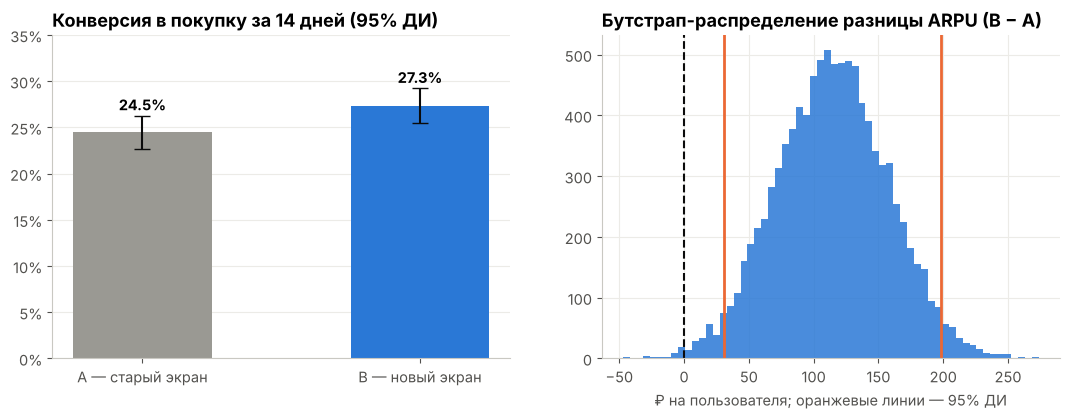

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

conv = ab_result.loc["purchased"]
n = {"A": len(a), "B": len(b)}
for i, (g, color) in enumerate([("A", GREY), ("B", BLUE)]):
    p = conv[g]
    err = 1.96 * np.sqrt(p * (1 - p) / n[g])
    axes[0].bar(i, p * 100, color=color, width=0.5)
    axes[0].errorbar(i, p * 100, yerr=err * 100, color="#0b0b0b", capsize=6, lw=1.5)
    axes[0].text(i, p * 100 + err * 100 + 0.6, f"{p:.1%}", ha="center", fontweight="bold")
axes[0].set_xticks([0, 1], ["A — старый экран", "B — новый экран"])
axes[0].set_ylim(0, 35)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].grid(axis="x", visible=False)
axes[0].set_title("Конверсия в покупку за 14 дней (95% ДИ)")

axes[1].hist(boot_diff, bins=60, color=BLUE, alpha=0.85)
axes[1].axvline(0, color="#0b0b0b", lw=1.5, ls="--")
for v in (ci_low, ci_high):
    axes[1].axvline(v, color=ORANGE, lw=2)
axes[1].set_title("Бутстрап-распределение разницы ARPU (B − A)")
axes[1].set_xlabel("₽ на пользователя; оранжевые линии — 95% ДИ")
fig.savefig(FIG_DIR / "06_ab_test.png", bbox_inches="tight")
plt.show()

### 7.5 Мощность теста

Проверим, достаточно ли было пользователей, чтобы надёжно ловить эффект такого размера (мощность 80%).

In [21]:
def sample_size_per_group(p_base, mde_abs, alpha=0.05, power=0.8):
    p_new = p_base + mde_abs
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_base * (1 - p_base) + p_new * (1 - p_new)
    return int(np.ceil((z_a + z_b) ** 2 * var / mde_abs ** 2))

p_base = ab_result.loc["purchased", "A"]
for mde in [0.02, 0.03, 0.05]:
    print(f"MDE {mde*100:.0f} п.п. -> нужно {sample_size_per_group(p_base, mde):,} пользователей в группе")
print(f"\nФактически в группах: {len(a):,} и {len(b):,}")

# какой минимальный эффект тест мог надёжно обнаружить при фактическом размере групп
achievable = next(m / 1000 for m in range(5, 200) if sample_size_per_group(p_base, m / 1000) <= min(len(a), len(b)))
print(f"Достижимый MDE при таком размере групп: ≈{achievable * 100:.1f} п.п.")

MDE 2 п.п. -> нужно 7,445 пользователей в группе
MDE 3 п.п. -> нужно 3,349 пользователей в группе
MDE 5 п.п. -> нужно 1,233 пользователей в группе

Фактически в группах: 2,191 и 2,172
Достижимый MDE при таком размере групп: ≈3.8 п.п.

### 7.6 Итог A/B-теста

- Разбиение корректно (SRM-тест не выявил перекоса, состав групп одинаковый).
- **Конверсия в покупку выросла с 24.5% до 27.3% (+2.9 п.п., +12% относительно контроля), p = 0.03** — статистически значимо при α = 0.05.
- Рост объясняется именно экраном оформления: конверсия checkout → purchase выросла с 60% до 71% (p < 0.001), а доля дошедших до checkout значимо не изменилась (p = 0.17) — guardrail в порядке.
- ARPU за 14 дней вырос с 540 до 655 ₽ (+21%), 95% бутстрап-интервал разницы [+31; +198] ₽ не включает 0; средний чек значимо не изменился (Mann-Whitney p = 0.71) — новый экран не «срезает» крупные заказы.
- Оговорка про мощность: при ~2 200 пользователях в группе тест с мощностью 80% надёжно ловит эффект от ≈3.7 п.п. Наблюдаемый эффект (2.9 п.п.) меньше, поэтому доверительный интервал широкий — [+0.3; +5.5] п.п.: эффект положительный, но может оказаться скромнее точечной оценки. В следующих тестах размер выборки стоит рассчитывать заранее и держать тест дольше.

**Рекомендация:** раскатить новый экран оформления на всех пользователей и продолжить мониторинг конверсии checkout → purchase после релиза.

## 8. Общие выводы и рекомендации

| # | Находка | Рекомендация |
|---|---|---|
| 1 | 3 августа DAU упал в ~7 раз из-за сбоя логирования | Настроить алерт на резкое падение числа событий; исключать этот день из сравнений |
| 2 | Наибольшие потери в воронке — на экране оформления (−31%) | Раскатить новый экран оформления (выиграл A/B-тест) |
| 3 | Рекламный трафик хуже удерживается и приносит на ~30–40% меньше ARPU | Сопоставить ARPU с CAC по рекламным кампаниям; перераспределить бюджет в пользу эффективных |
| 4 | Реферальные пользователи — самые ценные | Масштабировать реферальную программу |
| 5 | Android-пользователи удерживаются хуже iOS | Проверить crash rate и скорость Android-приложения |
| 6 | Sticky factor ≈ 8% и не растёт | Работать над возвратом в первые дни: push-уведомления, персональные подборки |

**Что можно улучшить в анализе:** добавить данные о маркетинговых расходах (для расчёта CAC/ROMI), анализ LTV по когортам и сегментацию по категориям товаров.